In [1]:
from pathlib import Path

import hdbscan
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
print('Libraries loaded')

Libraries loaded


### Load CSV & Prepare features by imputing missing values with medians and standardising

In [2]:
panel = pd.read_csv("panel_cluster_ready.csv", parse_dates=["date"])
FEATURES = [
    "ltv", "loop_depth", "distance_to_liq",
    "ltv_vol_7d", "ltv_vol_14d",
    "rebal_freq_7d", "rebal_freq_30d", "days_since_rebalance",
    "ltv_lag_7", "carry_spread", "carry_spread_levered",
]
X = panel[FEATURES].fillna(panel[FEATURES].median())
X_scaled = StandardScaler().fit_transform(X)

In [3]:
panel["cluster"] = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5).fit_predict(X_scaled)
print(panel["cluster"].value_counts().sort_index())
print(f"noise: {(panel['cluster'] == -1).mean():.1%}")

cluster
-1     626
 0      35
 1      46
 2      31
 3     270
 4      20
 5     132
 6      22
 7      26
 8      49
 9      19
 10     57
 11     15
 12     44
 13     29
 14     65
 15     55
 16     36
 17     52
 18     21
 19     47
 20     16
 21     39
 22     39
 23     47
 24     40
 25     52
 26     57
 27     36
 28     47
Name: count, dtype: int64
noise: 30.2%


HDBSCAN creates many density-based clusters on 11 scaled features based on closeness in feature space. Each day gets a cluster label, or -1 (noise) if it doesn't fit any dense group. On the full 24-whale panel (2,070 days) the untuned fit splits into ~29 micro-clusters with ~30% of days as noise.

A cluster needs at least 15 similar days to form a cluster (`min_cluster_size=15`), and each day is judged using its 5 nearest neighbours (`min_samples=5`).

### PCA plot coloured by cluster

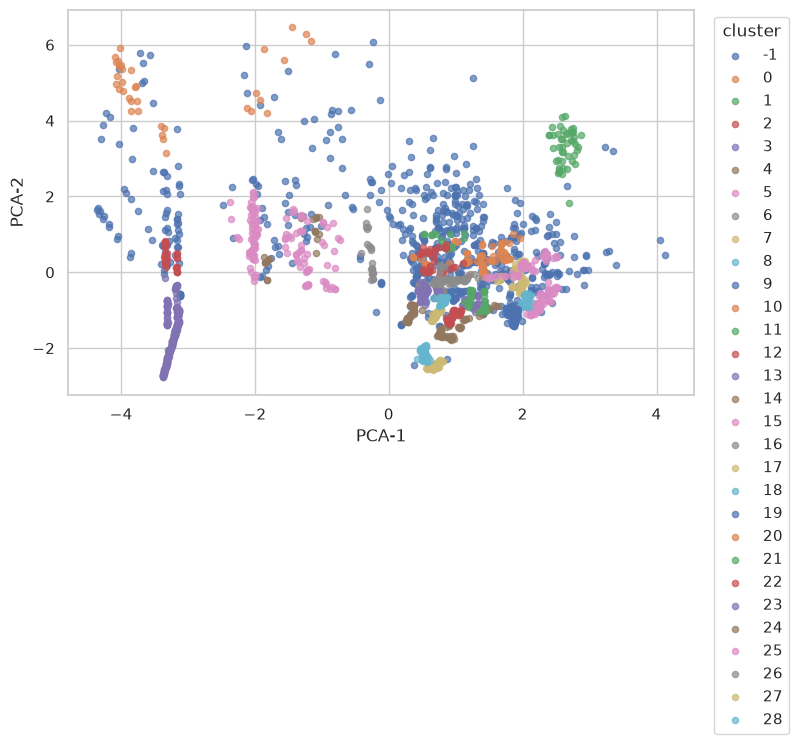

In [4]:
pca = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
panel["x"], panel["y"] = pca[:, 0], pca[:, 1]

fig, ax = plt.subplots(figsize=(9, 5))
for c in sorted(panel["cluster"].unique()):
    s = panel[panel["cluster"] == c]
    ax.scatter(s["x"], s["y"], label=c, alpha=0.7, s=20)
ax.legend(title="cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_xlabel("PCA-1")
ax.set_ylabel("PCA-2")
fig.subplots_adjust(right=0.82)
plt.show()

On the full 24-whale panel the untuned fit produces ~29 clusters plus a large noise band (-1). Broadly:
- Cluster -1 (noise, ~30% of days) is scattered around the middle and edges — days that sit between dense groups.
- A far-left group captures low leverage / high distance_to_liq days, well separated from the looping whales.
- Top/right groups capture very high ltv, loop_depth, and carry_spread_levered — max-leverage days clear of the main cloud.
- Several high-leverage groups split by rebalancing recency (fresher vs staler days since rebalance) with little overlap.
- A bottom group has high ltv but negative carry_spread — underwater-on-carry days.
- The centre-right holds the largest active-loop block (ltv ~90%, moderate loop_depth), with a nearby group that rebalances more frequently.

The main problem is fragmentation: ~29 micro-clusters is far too many for clean archetypes, and many are dominated by a single whale (W-11 in particular). This motivates the balanced fit in `03`.

### PCA plot coloured by `whale_id`

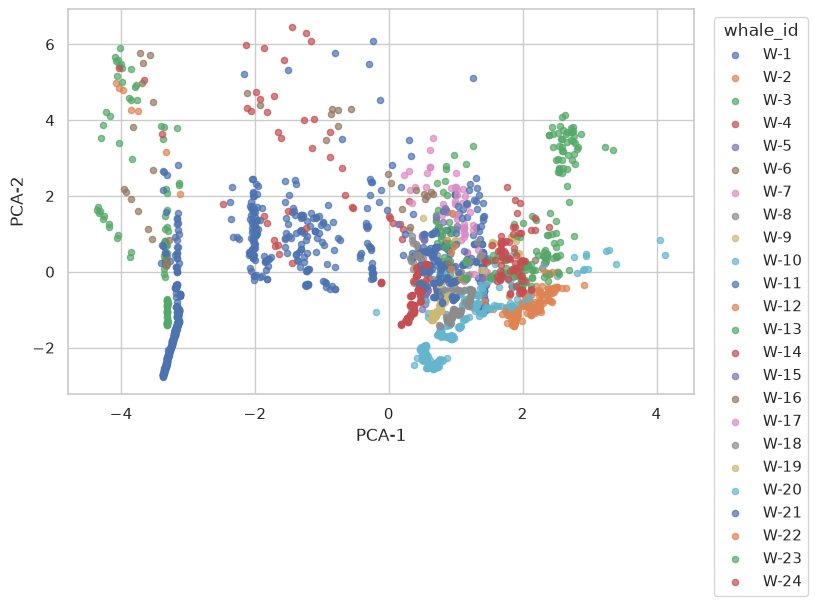

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
for w in sorted(panel["whale_id"].unique(), key=lambda w: int(w.split("-")[1])):
    s = panel[panel["whale_id"] == w]
    ax.scatter(s["x"], s["y"], label=w, alpha=0.7, s=20)
ax.legend(title="whale_id", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_xlabel("PCA-1")
ax.set_ylabel("PCA-2")
fig.subplots_adjust(right=0.82)
plt.show()

This plot shows where each whale’s days sit in the same PCA space, so you can see how they spread across leverage and rebalancing or carry.

The panel now spans all 24 whales (W-1..W-17 Morpho, W-18..W-24 Aave); W-17 has only 1 clusterable day.

W-3 is still the most versatile and spans the widest PCA area. W-11 (622 active days) dominates day count and pulls the untuned fit; W-10 and W-13 add long high-LTV stretches. The Aave whales (W-18..W-24) sit in the high-LTV region alongside the aggressive Morpho whales.

Most other whales sit in tighter patches, which is why baseline clustering often lines up with who is trading rather than a shared strategy type. This is why `03` balances per-whale before fitting.

In [6]:
panel.groupby("cluster")[FEATURES].mean().round(3)

,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
cluster,,,,,,,,,,,
-1,0.700,7.348,0.219,0.019,0.050,1.837,5.610,8.297,0.692,8.180,49.582
0,0.166,0.771,0.799,0.399,0.352,2.314,5.914,1.514,0.889,3.292,2.313
1,0.958,24.043,0.007,0.000,0.001,5.109,18.565,0.435,0.959,3.691,88.769
2,0.000,0.000,0.931,0.000,0.000,1.452,9.065,2.839,0.000,3.359,0.000
3,0.000,0.000,0.872,0.000,0.000,0.000,0.822,71.411,0.000,4.918,0.000
4,0.327,1.550,0.533,0.002,0.002,1.650,8.300,2.850,0.329,24.370,38.507
5,0.332,1.485,0.528,0.009,0.020,1.803,8.167,3.106,0.355,9.623,14.234
6,0.650,3.000,0.210,0.003,0.015,0.773,8.955,7.364,0.658,3.655,10.966
7,0.825,6.000,0.090,0.001,0.001,0.000,0.000,195.423,0.826,10.313,61.875


Untuned HDBSCAN still finds interpretable risk states (flap, max loop, stale, negative carry, active rebal, etc) but:
- there are far too many clusters (~29 + noise) for clean archetypes on 2,070 days.
- a large share of days (~30%) land in cluster -1 (noise).
- several micro-clusters are dominated by one whale (W-11 in particular).

`03_balanced_clustering.ipynb` balances whales, tunes `min_cluster_size`, and assigns centroids for 3–4 cross-whale archetypes.